# E-commerce Customer Purchase Conversion Prediction
### AnalystLab Africa — Experience Lab, Week 2 | Track 3: Machine Learning Engineering

**Project objective:** Build and evaluate a machine-learning classifier that estimates whether an e-commerce website session will result in a purchase.

This notebook documents the workflow from raw data inspection through target construction, exploratory analysis, feature engineering, chronological validation, model comparison, final testing, and business interpretation.

> **Reproducibility:** Keep this notebook in the project's `notebooks/` folder. Run it with the project root as the working directory, or allow the path-detection cell below to locate the project. The three original CSV files must be present in `data/raw/`. They are intentionally excluded from the public GitHub repository because they are source datasets.

> **Leakage prevention:** The core model uses session-level information available at or around session creation. Pageview behaviour and order details are not used as predictors because they may occur after the session begins or after conversion.

## 1. Business problem and machine-learning objective

An e-commerce business receives many website sessions, but only a small proportion result in purchases. Marketing and product teams need a way to identify sessions that are more likely to convert so they can better understand customer behaviour and evaluate opportunities to improve conversion.

**Machine-learning task:** Binary classification.

- `converted = 1`: at least one order is associated with the website session.
- `converted = 0`: no order is associated with the website session.

**Primary model:** Logistic Regression, as required by the assignment.

**Evaluation approach:** A chronological 80/20 train/test split. Earlier sessions are used for training and later sessions are held out for final testing. This better reflects the intended use case than randomly mixing past and future sessions.

**Core predictors:**
- `device_type`
- `utm_source`
- `utm_campaign`
- `utm_content`
- `http_referer`
- `is_repeat_session`

The model's predictions are decision-support signals, not guarantees that an individual session will purchase.

## 2. Environment and imports

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.0.5
numpy: 2.5.2


## 3. Locate the project and load the raw datasets

In [2]:
# Find the project root whether the notebook is launched from the project
# directory or from its notebooks/ subdirectory.
possible_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p.resolve() for p in possible_roots
     if (p / "data" / "raw").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project data/raw folder. "
        "Open the notebook from the Customer_Purchase_Conversion_Prediction project."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"

sessions_path = RAW_DIR / "website_sessions.csv"
pageviews_path = RAW_DIR / "website_pageviews.csv"
orders_path = RAW_DIR / "orders_mav.csv"

for path in [sessions_path, pageviews_path, orders_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required dataset not found: {path}")

sessions = pd.read_csv(sessions_path)
pageviews = pd.read_csv(pageviews_path)
orders = pd.read_csv(orders_path)

print("Project root:", PROJECT_ROOT)
print("Sessions:", sessions.shape)
print("Pageviews:", pageviews.shape)
print("Orders:", orders.shape)

Project root: C:\Users\user\Documents\computational-materials\Customer_Purchase_Conversion_Prediction
Sessions: (472871, 9)
Pageviews: (1048575, 4)
Orders: (32313, 8)


## 4. Initial data inspection

In [3]:
print("SESSIONS")
display(sessions.head())
print("\nPAGEVIEWS")
display(pageviews.head())
print("\nORDERS")
display(orders.head())

print("\nColumn names")
print("Sessions:", sessions.columns.tolist())
print("Pageviews:", pageviews.columns.tolist())
print("Orders:", orders.columns.tolist())

SESSIONS


,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,3/19/2012 8:04,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,3/19/2012 8:16,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,3/19/2012 8:26,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,3/19/2012 8:37,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,3/19/2012 9:00,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com



PAGEVIEWS


,website_pageview_id,created_at,website_session_id,pageview_url
0,1,3/19/2012 8:04,1,/home
1,2,3/19/2012 8:16,2,/home
2,3,3/19/2012 8:26,3,/home
3,4,3/19/2012 8:37,4,/home
4,5,3/19/2012 9:00,5,/home



ORDERS


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,3/19/2012 10:42,20,20,1,1,49.99,19.49
1,2,3/19/2012 19:27,104,104,1,1,49.99,19.49
2,3,3/20/2012 6:44,147,147,1,1,49.99,19.49
3,4,3/20/2012 9:41,160,160,1,1,49.99,19.49
4,5,3/20/2012 11:28,177,177,1,1,49.99,19.49



Column names
Sessions: ['website_session_id', 'created_at', 'user_id', 'is_repeat_session', 'utm_source', 'utm_campaign', 'utm_content', 'device_type', 'http_referer']
Pageviews: ['website_pageview_id', 'created_at', 'website_session_id', 'pageview_url']
Orders: ['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']


In [4]:
datasets = {
    "sessions": sessions,
    "pageviews": pageviews,
    "orders": orders,
}

quality_rows = []
for name, frame in datasets.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "duplicate_rows": int(frame.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
        "missing_percentage": round(frame.isna().sum().sum() / frame.size * 100, 3),
    })

display(pd.DataFrame(quality_rows))

print("\nMissing values in sessions:")
display(sessions.isna().sum().to_frame("missing_values"))

print("\nUnique key checks:")
print("Unique session IDs:", sessions["website_session_id"].nunique())
print("Unique pageview IDs:", pageviews["website_pageview_id"].nunique())
print("Unique order IDs:", orders["order_id"].nunique())
print("Unique order session IDs:", orders["website_session_id"].nunique())

,dataset,rows,columns,duplicate_rows,missing_cells,missing_percentage
0,sessions,472871,9,0,289901,6.812
1,pageviews,1048575,4,0,0,0.000
2,orders,32313,8,0,0,0.000



Missing values in sessions:


,missing_values
website_session_id,0
created_at,0
user_id,0
is_repeat_session,0
utm_source,83328
utm_campaign,83328
utm_content,83328
device_type,0
http_referer,39917



Unique key checks:
Unique session IDs: 472871
Unique pageview IDs: 1048575
Unique order IDs: 32313
Unique order session IDs: 32313


## 5. Relationship integrity and temporal checks

The session table is the modelling population. Orders are linked to sessions using `website_session_id`. Pageviews are inspected for relationship integrity, but are not included as predictors in the core model.

In [5]:
session_ids = set(sessions["website_session_id"])
pageview_session_ids = set(pageviews["website_session_id"])
order_session_ids = set(orders["website_session_id"])

print("Pageview sessions missing from sessions:", len(pageview_session_ids - session_ids))
print("Order sessions missing from sessions:", len(order_session_ids - session_ids))
print("Sessions without pageviews:", len(session_ids - pageview_session_ids))

sessions_check = sessions[["website_session_id", "created_at"]].copy()
orders_check = orders[["website_session_id", "created_at"]].copy()
sessions_check["created_at"] = pd.to_datetime(sessions_check["created_at"], errors="coerce")
orders_check["created_at"] = pd.to_datetime(orders_check["created_at"], errors="coerce")

temporal_check = orders_check.merge(
    sessions_check,
    on="website_session_id",
    suffixes=("_order", "_session"),
    how="left",
)
print(
    "Orders dated before their session:",
    int((temporal_check["created_at_order"] < temporal_check["created_at_session"]).sum())
)
print(
    "Orders with missing session timestamp:",
    int(temporal_check["created_at_session"].isna().sum())
)

Pageview sessions missing from sessions: 0
Order sessions missing from sessions: 0
Sessions without pageviews: 50915
Orders dated before their session: 0
Orders with missing session timestamp: 0


## 6. Construct the conversion target

In [6]:
# Each unique session with an associated order is labelled as converted.
converted_session_ids = set(orders["website_session_id"])

modeling = sessions.copy()
modeling["created_at"] = pd.to_datetime(modeling["created_at"], errors="coerce")
modeling["converted"] = modeling["website_session_id"].isin(converted_session_ids).astype("int8")

target_counts = modeling["converted"].value_counts().sort_index()
target_summary = pd.DataFrame({
    "sessions": target_counts,
    "percentage": (target_counts / len(modeling) * 100).round(4)
})
display(target_summary)

print("Total sessions:", len(modeling))
print("Unique converted sessions:", modeling.loc[modeling["converted"] == 1, "website_session_id"].nunique())
print("Target conversion rate:", round(modeling["converted"].mean() * 100, 4), "%")

assert modeling["website_session_id"].is_unique
assert modeling["converted"].sum() == orders["website_session_id"].nunique()

,sessions,percentage
converted,,
0,440558,93.1666
1,32313,6.8334


Total sessions: 472871
Unique converted sessions: 32313
Target conversion rate: 6.8334 %


## 7. Exploratory data analysis

Overall conversion rate: 6.83%


,sessions,conversions,conversion_rate
device_type,,,
desktop,327027,27805,8.502356
mobile,145844,4508,3.090974


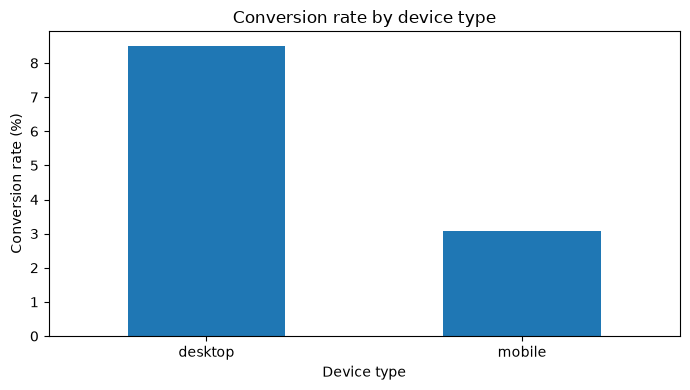

In [7]:
overall_conversion = modeling["converted"].mean()
print(f"Overall conversion rate: {overall_conversion:.2%}")

device_summary = (
    modeling.groupby("device_type", dropna=False)
    .agg(sessions=("converted", "size"), conversions=("converted", "sum"),
         conversion_rate=("converted", "mean"))
    .sort_values("conversion_rate", ascending=False)
)
device_summary["conversion_rate"] *= 100
display(device_summary)

device_summary["conversion_rate"].plot(kind="bar", figsize=(7, 4))
plt.title("Conversion rate by device type")
plt.ylabel("Conversion rate (%)")
plt.xlabel("Device type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,sessions,conversions,conversion_rate
session_type,,,
New,394318,26164,6.635254
Repeat,78553,6149,7.827836


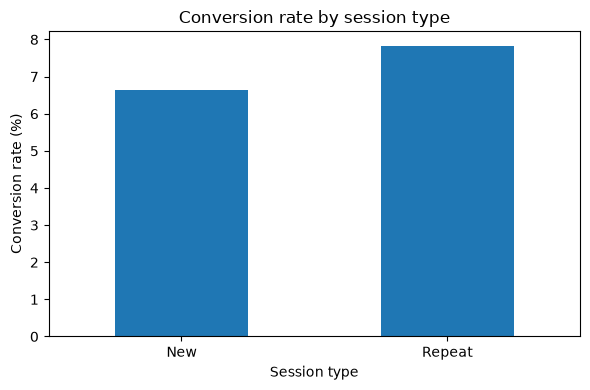

In [8]:
modeling["session_type"] = np.where(
    modeling["is_repeat_session"].fillna(0).astype(int) == 1,
    "Repeat",
    "New"
)

session_type_summary = (
    modeling.groupby("session_type")
    .agg(sessions=("converted", "size"), conversions=("converted", "sum"),
         conversion_rate=("converted", "mean"))
)
session_type_summary["conversion_rate"] *= 100
display(session_type_summary)

session_type_summary["conversion_rate"].plot(kind="bar", figsize=(6, 4))
plt.title("Conversion rate by session type")
plt.ylabel("Conversion rate (%)")
plt.xlabel("Session type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Missing marketing values are kept as a distinct category.
marketing_columns = ["utm_source", "utm_campaign", "utm_content", "http_referer"]
marketing_summary = []
for col in marketing_columns:
    temp = modeling[col].fillna("Missing")
    grouped = modeling.assign(_category=temp).groupby("_category")["converted"].agg(
        sessions="size", conversions="sum", conversion_rate="mean"
    )
    grouped["feature"] = col
    grouped["category"] = grouped.index.astype(str)
    marketing_summary.append(grouped.reset_index(drop=True))

marketing_summary = pd.concat(marketing_summary, ignore_index=True)
marketing_summary["conversion_rate"] *= 100
display(marketing_summary.sort_values(["feature", "sessions"], ascending=[True, False]))

,sessions,conversions,conversion_rate,feature,category
18,351237,23852,6.790856,http_referer,https://www.gsearch.com
17,71032,5262,7.407929,http_referer,https://www.bsearch.com
16,39917,2856,7.154846,http_referer,Missing
19,10685,343,3.210108,http_referer,https://www.socialbook.com
7,337615,22640,6.705863,utm_campaign,nonbrand
4,83328,6118,7.342070,utm_campaign,Missing
5,41243,3212,7.787988,utm_campaign,brand
6,5590,288,5.152057,utm_campaign,desktop_targeted
8,5095,55,1.079490,utm_campaign,pilot
12,282706,18822,6.657800,utm_content,g_ad_1


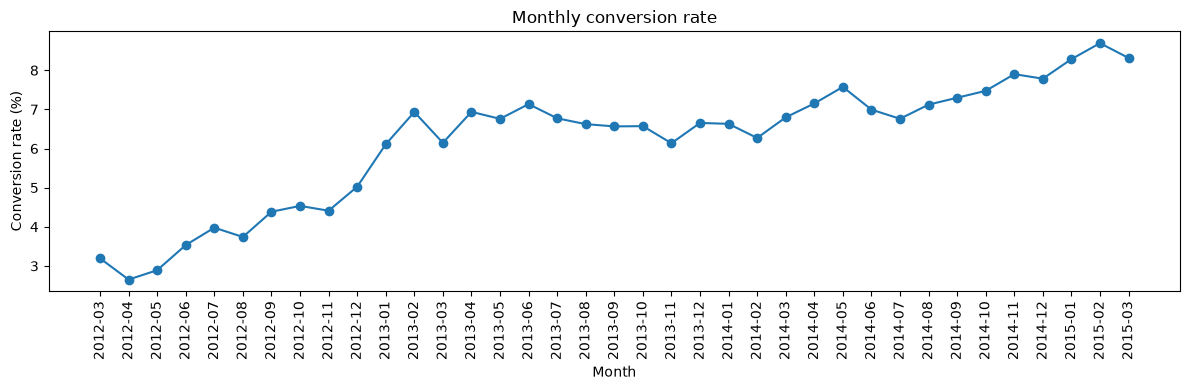

In [10]:
monthly = (
    modeling.dropna(subset=["created_at"])
    .assign(month=lambda d: d["created_at"].dt.to_period("M").astype(str))
    .groupby("month")
    .agg(sessions=("converted", "size"), conversions=("converted", "sum"))
)
monthly["conversion_rate"] = monthly["conversions"] / monthly["sessions"] * 100

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(monthly.index, monthly["conversion_rate"], marker="o")
ax1.set_title("Monthly conversion rate")
ax1.set_xlabel("Month")
ax1.set_ylabel("Conversion rate (%)")
ax1.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

### EDA interpretation

The overall conversion rate is low, so the target is imbalanced. The EDA compares conversion rates across device, session type and marketing categories. These are descriptive associations; they do not establish that a particular device or marketing channel causes conversion.

In the completed analysis, desktop sessions had a substantially higher observed conversion rate than mobile sessions. Repeat sessions also had a somewhat higher rate than new sessions. These patterns motivate including the corresponding features, while still requiring model-based evaluation on later sessions.

## 8. Feature engineering and leakage control

In [11]:
# Fill missing categorical values with an explicit category.
for col in marketing_columns + ["device_type"]:
    modeling[col] = modeling[col].fillna("Missing").astype(str)

modeling["is_repeat_session"] = modeling["is_repeat_session"].fillna(0).astype(int)

# Time-derived features are included only in the extended comparison.
modeling["session_hour"] = modeling["created_at"].dt.hour
modeling["session_day_of_week"] = modeling["created_at"].dt.dayofweek
modeling["session_month"] = modeling["created_at"].dt.month

CORE_CATEGORICAL = [
    "device_type", "utm_source", "utm_campaign", "utm_content", "http_referer"
]
CORE_NUMERICAL = ["is_repeat_session"]
CORE_FEATURES = CORE_CATEGORICAL + CORE_NUMERICAL

EXTENDED_NUMERICAL = CORE_NUMERICAL + [
    "session_hour", "session_day_of_week", "session_month"
]
EXTENDED_FEATURES = CORE_CATEGORICAL + EXTENDED_NUMERICAL

TARGET = "converted"

print("Core features:", CORE_FEATURES)
print("Extended features:", EXTENDED_FEATURES)
print("Target:", TARGET)
print("Missing values in core features:", int(modeling[CORE_FEATURES].isna().sum().sum()))

Core features: ['device_type', 'utm_source', 'utm_campaign', 'utm_content', 'http_referer', 'is_repeat_session']
Extended features: ['device_type', 'utm_source', 'utm_campaign', 'utm_content', 'http_referer', 'is_repeat_session', 'session_hour', 'session_day_of_week', 'session_month']
Target: converted
Missing values in core features: 0


**Leakage controls applied:**
- Order identifiers, order values, product details and cost fields are not predictors.
- Pageview counts, pageview URLs and pageview sequences are not predictors.
- User and session identifiers are retained only for record linkage/auditing, not model inputs.
- The target is derived from whether an order is associated with the session.
- The chronological test set is held out until final evaluation.

## 9. Chronological train/test split

In [12]:
# Sort chronologically and keep sessions with identical timestamps together.
modeling = modeling.sort_values(
    ["created_at", "website_session_id"]
).reset_index(drop=True)

split_position = int(len(modeling) * 0.80)
split_timestamp = modeling.loc[split_position, "created_at"]

train_df = modeling[modeling["created_at"] < split_timestamp].copy()
test_df = modeling[modeling["created_at"] >= split_timestamp].copy()

# If a timestamp tie spans the nominal split, the strict timestamp condition
# keeps all records at that timestamp on the test side.
X_train_core = train_df[CORE_FEATURES].copy()
X_test_core = test_df[CORE_FEATURES].copy()
X_train_extended = train_df[EXTENDED_FEATURES].copy()
X_test_extended = test_df[EXTENDED_FEATURES].copy()

y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

split_summary = pd.DataFrame([
    {
        "split": "Train",
        "records": len(train_df),
        "start": train_df["created_at"].min(),
        "end": train_df["created_at"].max(),
        "conversion_rate": y_train.mean(),
    },
    {
        "split": "Test",
        "records": len(test_df),
        "start": test_df["created_at"].min(),
        "end": test_df["created_at"].max(),
        "conversion_rate": y_test.mean(),
    },
])
display(split_summary)

print("Split timestamp:", split_timestamp)
print("Train shape:", X_train_core.shape)
print("Test shape:", X_test_core.shape)
print("Train target counts:\n", y_train.value_counts().sort_index())
print("Test target counts:\n", y_test.value_counts().sort_index())

,split,records,start,end,conversion_rate
0,Train,378295,2012-03-19 08:04:00,2014-11-28 23:31:00,0.064844
1,Test,94576,2014-11-28 23:32:00,2015-03-19 07:59:00,0.082294


Split timestamp: 2014-11-28 23:32:00
Train shape: (378295, 6)
Test shape: (94576, 6)
Train target counts:
 converted
0    353765
1     24530
Name: count, dtype: int64
Test target counts:
 converted
0    86793
1     7783
Name: count, dtype: int64


## 10. Preprocessing and evaluation helper functions

In [13]:
def make_preprocessor(categorical_features, numerical_features, dense=False):
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10,
            sparse_output=not dense
        )),
    ])

    numerical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    return ColumnTransformer(
        transformers=[
            ("categorical", categorical_pipeline, categorical_features),
            ("numerical", numerical_pipeline, numerical_features),
        ],
        remainder="drop",
    )


def metric_row(name, y_true, y_pred, y_probability):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_probability),
        "average_precision": average_precision_score(y_true, y_probability),
        "brier_score": brier_score_loss(y_true, y_probability),
    }


def evaluate_at_default_threshold(model, X, y):
    probability = model.predict_proba(X)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    return metric_row("model", y, prediction, probability), prediction, probability

## 11. Train the required Logistic Regression baseline

In [14]:
core_categorical = CORE_CATEGORICAL
core_numerical = CORE_NUMERICAL

core_preprocessor = make_preprocessor(core_categorical, core_numerical)
core_logistic_regression = Pipeline(steps=[
    ("preprocessor", core_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )),
])

core_logistic_regression.fit(X_train_core, y_train)

core_probability = core_logistic_regression.predict_proba(X_test_core)[:, 1]
core_prediction = (core_probability >= 0.5).astype(int)

core_metrics = metric_row(
    "Logistic Regression — core",
    y_test,
    core_prediction,
    core_probability
)
display(pd.DataFrame([core_metrics]).set_index("model"))

,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
model,,,,,,,
Logistic Regression — core,0.377527,0.103858,0.860465,0.185346,0.605217,0.105153,0.245395


## 12. Compare core and extended Logistic Regression

In [15]:
extended_preprocessor = make_preprocessor(
    CORE_CATEGORICAL,
    EXTENDED_NUMERICAL
)
extended_logistic_regression = Pipeline(steps=[
    ("preprocessor", extended_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )),
])

extended_logistic_regression.fit(X_train_extended, y_train)
extended_probability = extended_logistic_regression.predict_proba(X_test_extended)[:, 1]
extended_prediction = (extended_probability >= 0.5).astype(int)

extended_metrics = metric_row(
    "Logistic Regression — extended",
    y_test,
    extended_prediction,
    extended_probability
)
display(pd.DataFrame([core_metrics, extended_metrics]).set_index("model"))

,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
model,,,,,,,
Logistic Regression — core,0.377527,0.103858,0.860465,0.185346,0.605217,0.105153,0.245395
Logistic Regression — extended,0.377527,0.103858,0.860465,0.185346,0.606179,0.106581,0.248058


## 13. Chronological validation and alternative model comparison

To compare model families without using the final test set, a second chronological split is made within the original training period. Preprocessing is fitted only on the earlier model-training portion. The final test set remains untouched until the final model evaluation.

The alternative models are included as challengers. Hyperparameter tuning is not performed in this project.

In [16]:
inner_position = int(len(train_df) * 0.80)
validation_timestamp = train_df.iloc[inner_position]["created_at"]

model_train_df = train_df[train_df["created_at"] < validation_timestamp].copy()
validation_df = train_df[train_df["created_at"] >= validation_timestamp].copy()

X_model_train = model_train_df[CORE_FEATURES]
y_model_train = model_train_df[TARGET]
X_validation = validation_df[CORE_FEATURES]
y_validation = validation_df[TARGET]

print("Model training records:", len(model_train_df))
print("Validation records:", len(validation_df))
print("Model training conversion rate:", round(y_model_train.mean(), 4))
print("Validation conversion rate:", round(y_validation.mean(), 4))

Model training records: 302636
Validation records: 75659
Model training conversion rate: 0.0623
Validation conversion rate: 0.0749


In [17]:
def build_core_pipeline(classifier, dense=False):
    preprocessor = make_preprocessor(
        CORE_CATEGORICAL,
        CORE_NUMERICAL,
        dense=dense
    )
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])


validation_models = {
    "Logistic Regression": build_core_pipeline(
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Random Forest": build_core_pipeline(
        RandomForestClassifier(
            n_estimators=150,
            max_depth=12,
            min_samples_leaf=20,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),
    "Gradient Boosting": build_core_pipeline(
        GradientBoostingClassifier(
            n_estimators=75,
            learning_rate=0.05,
            max_depth=2,
            subsample=0.8,
            random_state=RANDOM_STATE
        )
    ),
    "HistGradientBoosting": build_core_pipeline(
        HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE
        ),
        dense=True
    ),
}

validation_results = []
validation_fitted_models = {}

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_model_train
)

for name, estimator in validation_models.items():
    print("Training:", name)

    if name == "Gradient Boosting":
        estimator.fit(
            X_model_train,
            y_model_train,
            classifier__sample_weight=sample_weights
        )
    elif name == "HistGradientBoosting":
        estimator.fit(
            X_model_train,
            y_model_train,
            classifier__sample_weight=sample_weights
        )
    else:
        estimator.fit(X_model_train, y_model_train)

    val_prob = estimator.predict_proba(X_validation)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    row = metric_row(name, y_validation, val_pred, val_prob)
    validation_results.append(row)
    validation_fitted_models[name] = estimator

validation_comparison = pd.DataFrame(validation_results).set_index("model")
display(validation_comparison.sort_values("average_precision", ascending=False))

Training: Logistic Regression
Training: Random Forest
Training: Gradient Boosting
Training: HistGradientBoosting


,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
model,,,,,,,
Gradient Boosting,0.412112,0.09729,0.826954,0.174097,0.612264,0.098131,0.240248
Random Forest,0.412112,0.09729,0.826954,0.174097,0.611639,0.098035,0.240089
Logistic Regression,0.412112,0.09729,0.826954,0.174097,0.611904,0.098023,0.237702
HistGradientBoosting,0.412112,0.09729,0.826954,0.174097,0.608254,0.097676,0.234568


### Model comparison interpretation

Compare the models using several metrics rather than accuracy alone. Average precision is particularly informative for an imbalanced target because it summarises the precision-recall trade-off. ROC-AUC measures ranking ability across thresholds.

The completed project found only marginal differences among the model families. Gradient Boosting had slightly stronger validation ranking metrics, but the gain was small. Logistic Regression was retained as the final model because it is the assignment's required model and is relatively interpretable. This is a pragmatic selection, not evidence that it is a highly accurate predictor.

## 14. Final Logistic Regression model and untouched test evaluation

In [18]:
# Refit the selected core Logistic Regression pipeline on the complete
# original training period. Do not fit on the held-out test records.
final_model = build_core_pipeline(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
)
final_model.fit(X_train_core, y_train)

final_probability = final_model.predict_proba(X_test_core)[:, 1]
final_prediction = (final_probability >= 0.5).astype(int)

final_metrics = metric_row(
    "Final Logistic Regression",
    y_test,
    final_prediction,
    final_probability
)
display(pd.DataFrame([final_metrics]).set_index("model"))

print("Actual positive sessions:", int(y_test.sum()))
print("Predicted positive sessions:", int(final_prediction.sum()))

,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
model,,,,,,,
Final Logistic Regression,0.377527,0.103858,0.860465,0.185346,0.605217,0.105153,0.245395


Actual positive sessions: 7783
Predicted positive sessions: 64482


## 15. Confusion matrix and classification report

Confusion matrix:
[[29008 57785]
 [ 1086  6697]]
True negatives: 29,008
False positives: 57,785
False negatives: 1,086
True positives: 6,697

Classification report:
              precision    recall  f1-score   support

 No purchase       0.96      0.33      0.50     86793
    Purchase       0.10      0.86      0.19      7783

    accuracy                           0.38     94576
   macro avg       0.53      0.60      0.34     94576
weighted avg       0.89      0.38      0.47     94576



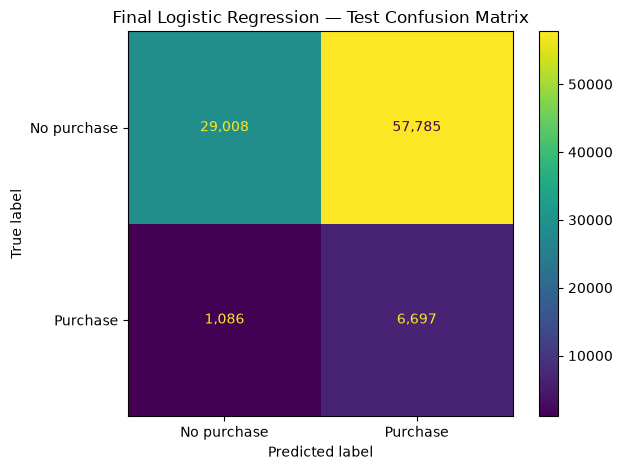

In [19]:
cm = confusion_matrix(y_test, final_prediction, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix:")
print(cm)
print(f"True negatives: {tn:,}")
print(f"False positives: {fp:,}")
print(f"False negatives: {fn:,}")
print(f"True positives: {tp:,}")

print("\nClassification report:")
print(classification_report(
    y_test,
    final_prediction,
    target_names=["No purchase", "Purchase"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No purchase", "Purchase"]
).plot(values_format=",")
plt.title("Final Logistic Regression — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 16. ROC and precision-recall curves

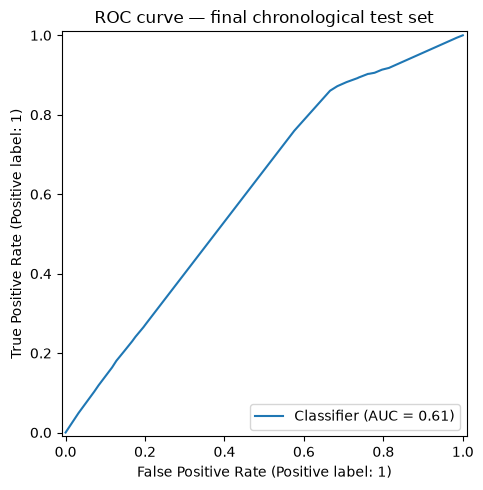

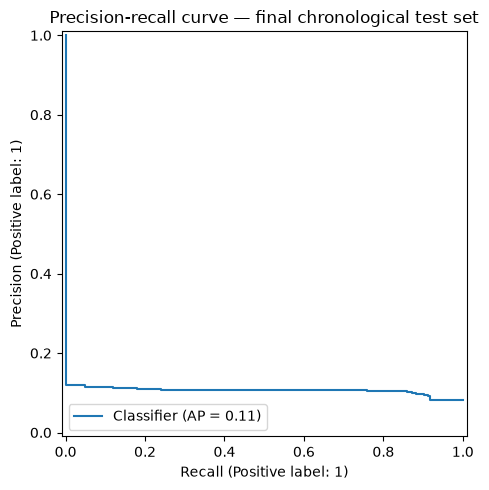

Test positive prevalence: 0.0823
Average precision: 0.1052


In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, final_probability, ax=ax)
ax.set_title("ROC curve — final chronological test set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, final_probability, ax=ax)
ax.set_title("Precision-recall curve — final chronological test set")
plt.tight_layout()
plt.show()

print("Test positive prevalence:", round(y_test.mean(), 4))
print("Average precision:", round(average_precision_score(y_test, final_probability), 4))

## 17. Threshold analysis

In [21]:
threshold_rows = []
for threshold in [0.10, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    pred_at_threshold = (final_probability >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "predicted_positive_sessions": int(pred_at_threshold.sum()),
        "precision": precision_score(y_test, pred_at_threshold, zero_division=0),
        "recall": recall_score(y_test, pred_at_threshold, zero_division=0),
        "f1": f1_score(y_test, pred_at_threshold, zero_division=0),
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results)

,threshold,predicted_positive_sessions,precision,recall,f1
0,0.10,94576,0.082294,1.000000,0.152073
1,0.20,94576,0.082294,1.000000,0.152073
2,0.25,94576,0.082294,1.000000,0.152073
3,0.30,93215,0.082991,0.993961,0.153191
4,0.35,73136,0.096095,0.902994,0.173705
5,0.40,66154,0.102579,0.871900,0.183562
6,0.45,64482,0.103858,0.860465,0.185346
7,0.50,64482,0.103858,0.860465,0.185346
8,0.55,19723,0.108148,0.274059,0.155093
9,0.60,12506,0.112426,0.180650,0.138597


**Threshold caution:** This table is diagnostic. The final model's 0.50 threshold is retained for the reported evaluation. A production threshold should be selected using business costs and validation data, not by choosing the best-looking result on the final test set.

## 18. Model interpretation — Logistic Regression coefficients

In [22]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_classifier = final_model.named_steps["classifier"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

coefficient_table = pd.DataFrame({
    "encoded_feature": encoded_feature_names,
    "coefficient": coefficients,
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
coefficient_table = coefficient_table.sort_values(
    "absolute_coefficient", ascending=False
)

display(coefficient_table.head(20))

,encoded_feature,coefficient,absolute_coefficient
1,categorical__device_type_mobile,-0.626225,0.626225
0,categorical__device_type_desktop,0.418988,0.418988
10,categorical__utm_campaign_pilot,-0.317987,0.317987
16,categorical__utm_content_social_ad_1,-0.317987,0.317987
21,categorical__http_referer_https://www.socialbo...,-0.273301,0.273301
5,categorical__utm_source_socialbook,-0.273301,0.273301
7,categorical__utm_campaign_brand,0.071564,0.071564
15,categorical__utm_content_g_ad_2,0.046609,0.046609
17,categorical__utm_content_social_ad_2,0.044686,0.044686
8,categorical__utm_campaign_desktop_targeted,0.044686,0.044686


,sum_absolute_coefficients
original_feature,
device_type,1.045213
utm_campaign,0.511703
utm_content,0.511703
utm_source,0.365679
http_referer,0.339364
is_repeat_session,0.043560


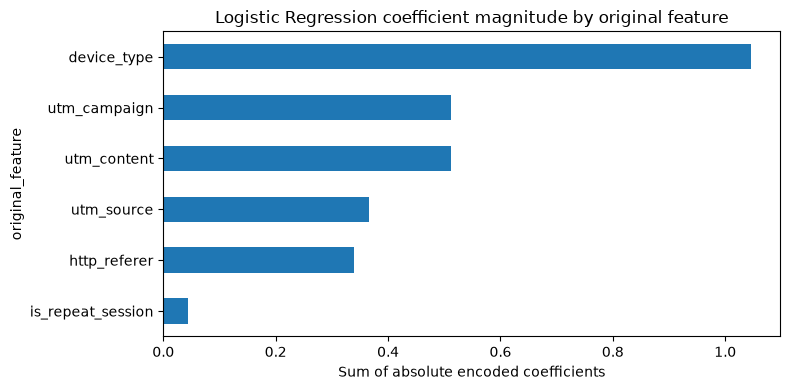

In [23]:
original_features = [
    "device_type", "utm_source", "utm_campaign",
    "utm_content", "http_referer", "is_repeat_session"
]

def get_original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]
    for feature in original_features:
        if name == feature or name.startswith(feature + "_"):
            return feature
    return name

coefficient_table["original_feature"] = (
    coefficient_table["encoded_feature"].map(get_original_feature)
)

grouped_importance = (
    coefficient_table.groupby("original_feature")["absolute_coefficient"]
    .sum()
    .sort_values(ascending=False)
    .to_frame("sum_absolute_coefficients")
)
display(grouped_importance)

grouped_importance["sum_absolute_coefficients"].sort_values().plot(
    kind="barh", figsize=(8, 4)
)
plt.title("Logistic Regression coefficient magnitude by original feature")
plt.xlabel("Sum of absolute encoded coefficients")
plt.tight_layout()
plt.show()

Coefficient interpretation:
- A positive coefficient increases the model's log-odds of conversion relative to the relevant reference category, holding other encoded features constant.
- A negative coefficient decreases those log-odds relative to the reference category.
- One-hot encoded categorical coefficients are relative to the encoder's representation and should not be interpreted as causal effects.
- Summed absolute coefficients are a rough feature-group comparison, not a causal or universally comparable measure of importance.

## 19. Probability-group review

In [24]:
probability_groups = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted_probability": final_probability,
})

probability_groups["probability_group"] = pd.cut(
    probability_groups["predicted_probability"],
    bins=[-np.inf, 0.2, 0.3, 0.4, 0.5, 0.6, np.inf],
    labels=["<0.20", "0.20–0.30", "0.30–0.40", "0.40–0.50", "0.50–0.60", ">=0.60"],
    right=False
)

probability_group_summary = (
    probability_groups.groupby("probability_group", observed=False)
    .agg(
        sessions=("actual", "size"),
        mean_predicted_probability=("predicted_probability", "mean"),
        observed_conversion_rate=("actual", "mean"),
    )
)
display(probability_group_summary)

,sessions,mean_predicted_probability,observed_conversion_rate
probability_group,,,
<0.20,0,NaN,NaN
0.20–0.30,1361,0.284766,0.034533
0.30–0.40,27061,0.320061,0.035106
0.40–0.50,1672,0.434261,0.053230
0.50–0.60,51976,0.551286,0.101797
>=0.60,12506,0.610972,0.112426


The predicted probabilities should not automatically be treated as calibrated purchase probabilities. The probability-group table compares average model scores with observed conversion rates. The completed analysis showed that the model's probability estimates were not well calibrated, so they should be treated cautiously.

## 20. Reproducibility check

In [25]:
# Recompute predictions from the same fitted model and confirm exact equality.
repeated_probability = final_model.predict_proba(X_test_core)[:, 1]
max_probability_difference = float(
    np.max(np.abs(final_probability - repeated_probability))
)

print("Maximum probability difference:", max_probability_difference)
print("Reproducibility passed:", np.allclose(
    final_probability,
    repeated_probability,
    rtol=0,
    atol=0
))

Maximum probability difference: 0.0
Reproducibility passed: True


## 21. Save notebook outputs and final model

In [26]:
# Outputs are kept in a dedicated folder so this notebook does not overwrite
# the existing staged scripts' reports or model artifacts.
NOTEBOOK_OUTPUT_DIR = PROJECT_ROOT / "notebook_outputs"
NOTEBOOK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import joblib

joblib.dump(final_model, NOTEBOOK_OUTPUT_DIR / "logistic_regression_notebook_model.joblib")

final_predictions_export = pd.DataFrame({
    "actual_converted": y_test.to_numpy(),
    "predicted_converted": final_prediction,
    "predicted_probability": final_probability,
})
final_predictions_export.to_csv(
    NOTEBOOK_OUTPUT_DIR / "final_test_predictions.csv",
    index=False
)

pd.DataFrame([final_metrics]).to_csv(
    NOTEBOOK_OUTPUT_DIR / "final_test_metrics.csv",
    index=False
)
threshold_results.to_csv(
    NOTEBOOK_OUTPUT_DIR / "threshold_analysis.csv",
    index=False
)
grouped_importance.to_csv(
    NOTEBOOK_OUTPUT_DIR / "grouped_feature_importance.csv"
)

print("Notebook outputs saved to:", NOTEBOOK_OUTPUT_DIR)

Notebook outputs saved to: C:\Users\user\Documents\computational-materials\Customer_Purchase_Conversion_Prediction\notebook_outputs


## 22. Business interpretation, recommendations and limitations

### What the final model tells us

The final Logistic Regression model achieved the following results on the later chronological test period:

- Accuracy: approximately **37.75%**
- Precision: approximately **10.39%**
- Recall: approximately **86.05%**
- F1-score: approximately **18.53%**
- ROC-AUC: approximately **0.605**
- Average precision: approximately **0.105**

The model identifies a large share of actual converting sessions, but it also flags many sessions that do not convert. Approximately 10 out of every 100 sessions flagged as positive actually converted at the selected threshold.

### Business recommendations

1. **Treat the model as an exploratory prioritisation tool.** Its high recall may help identify a broad pool of sessions for further analysis, but low precision makes it unsuitable for expensive one-to-one interventions without additional filtering.
2. **Investigate the mobile conversion gap.** Mobile sessions had a substantially lower observed conversion rate than desktop sessions. Review mobile page speed, navigation, checkout usability and payment experience.
3. **Review marketing performance by campaign and content.** Compare conversion rates alongside traffic volume and acquisition cost before reallocating spend. Small segments should be interpreted cautiously.
4. **Improve measurement quality.** Missing campaign and referrer information should be investigated so that marketing attribution is more reliable.
5. **Monitor model performance over time.** The later test period had a higher conversion prevalence than the training period, indicating temporal distribution shift.
6. **Revisit the decision threshold using business costs.** The appropriate threshold depends on the cost of false positives, the value of identifying a converting session and the capacity of the business to act.

### Limitations

- The final model has modest ranking performance and low precision.
- The target is imbalanced.
- The chronological test set has a different conversion rate from the training set.
- Marketing and device associations do not establish causation.
- The model uses a limited set of session-level predictors.
- Predicted probabilities are not demonstrated to be calibrated.
- The model does not establish that an intervention will cause a purchase.

### Future improvements

Potential next steps include collecting richer pre-conversion session signals, improving attribution data, evaluating calibration on a separate validation period, monitoring temporal drift, and testing business-specific decision thresholds. Any new features must be checked carefully to prevent target leakage.

## 23. Final project conclusion

This project developed an end-to-end binary classification workflow for e-commerce purchase conversion. It joined session and order data to construct a conversion target, inspected data quality and relationships, explored conversion patterns, engineered session-level features, used a chronological split, trained Logistic Regression and compared alternative classifiers, and evaluated the selected model on a held-out later period.

The Logistic Regression model achieved high recall but low precision and only modest ranking performance. It is therefore best treated as a baseline decision-support model rather than a reliable standalone purchase predictor. The analysis also identified mobile conversion and marketing measurement as areas worthy of further business investigation.

**End of notebook.**